# An Infinite Family of Apéry-like Recurrences for Euler’s Constant

Welcome to the supplementary notebook of the paper "An Infinite Family of Apéry-like Recurrences for Euler’s Constant". This notebook utilizes the [ramanujantools](https://github.com/RamanujanMachine/ramanujantools) python repository, which contains tools for exploring D-Finite sequences and Conservative Matrix Fields (CMFs).

The notebook covers:

1.   Code crash course: an optional tutorial of `ramanujantools`
2.   Examples of D-Finite sequence constructions and their convergence to $\gamma$

In [ ]:
# Installing all packages with explicit versions for reproducibility
! pip install tqdm==4.65.0 numpy==2.3.0 mpmath==1.3.0 sympy==1.14.0 gmpy2==2.2.0 python-flint==0.7.0
! pip install ramanujantools==0.0.8

  Using cached ramanujantools-0.0.8-py3-none-any.whl.metadata (3.8 kB)
Using cached ramanujantools-0.0.8-py3-none-any.whl (113 kB)


# Code crash course

In this very short section, we will cover the basic usage of `ramanujantools`. Specifically, we will showcase how to use the `Matrix` object, how to run the Cyclic Vector Method (CVM) algorithm to turn it into a `LinearRecurrence`, and how to evaluate `Limit` objects from these.

A major difference in the code from the mathematical paper is that vectors are not index-based in the code, and are represented through a dict-like object called `Position` (which inherits from `dict`).

In [ ]:
from types import SimpleNamespace
import pandas as pd
import mpmath as mp
import sympy as sp
from sympy.abc import x, y, n

from ramanujantools import Matrix, LinearRecurrence, Position

t = SimpleNamespace()

## Matrix
The `Matrix` object inherits directly from `sympy.Matrix`. It adds some utilities beyond it.

In [ ]:
t.m = Matrix([[x-y-5, x*2 +y], [3*x+4, 1+x*y]])
t.m

Matrix([
[x - y - 5, 2*x + y],
[  3*x + 4, x*y + 1]])

```python
Matrix.walk(self, trajectory: Position, iterations: int | List[int], start: Position) -> Matrix
```
receives a trajectory vector $t$, the amount of iterations of the walk $N$ (which could also be a list for multiple results), and the starting point $s$, and returns the walk matrix defined as $\prod_{i=0}^{N-1}m(s+i\cdot t)$, multiplying to the right.

Normally, this calculation would take a lot of time on `sympy`, even with the `gmpy2` backend. In `ramanujantools`, we have implemented this key logic using `python-flint`, which proves to be a very fast backend engine both for numeric and symbolic calculations.

In [ ]:
assert Matrix.eye(2) == t.m.walk(Position({x: 1, y: 1}), 0, Position({x: 0, y: 0}))
assert t.m.subs({x: 0, y: 0}) == t.m.walk(Position({x: 1, y: 1}), 1, Position({x: 0, y: 0}))
display("Numeric version:")
display(t.m.walk(Position({x: 2, y: 3}), 200, Position({x: 0, y: 0})))
display("Symbolic version:")
display(t.m.walk(Position({x: 2, y: 3}), 20, Position({x: n, y: n})))

'Numeric version:'

Matrix([
[-42379191212130092726714875785111027745270708521524857285789676467649620246188051743908834033120726244817215428583519188463652476590337813988901562012715885971571285699942301624283158979035117493468511284390120820412794445722908011013356768886924441280461824667803504189486669364012776187039788812589029079449146390697505579184707343908090356688380268157322899917556732808158159813458018698872166106827692949981342388797620410636173490952514311730737917135139606388509909043158543603448652451966974208152659011227205842845129452824155441685625787331412262656289613981504092267941675392591354659692131175434899673323730519991926678459019943863036395298401107762167751925076211194908721159542865608482977619665552551081346539459983763510231009996218885906928029532315161882203616522293879222323485531242106309478151992611531208032822312175536666803219628404594666734531722083063238942592269597668626330, -841283847772894542545039164938447307542710176357382523493081923627284266570826818832248

'Symbolic version:'

Matrix([
[                                              9*n**38 + 8049*n**37 + 3470184*n**36 + 960744768*n**35 + 191969845864*n**34 + 29498719906909*n**33 + 3627162769019322*n**32 + 366647937013521104*n**31 + 31064356732283542187*n**30 + 2238041065644195763919*n**29 + 138625931349288957666969*n**28 + 7445544008156035275933624*n**27 + 349076170230511722014923627*n**26 + 14360882850304672192430938288*n**25 + 520518322193695008267242365733*n**24 + 16673190773028884367801008160897*n**23 + 473042841481079015086616522936399*n**22 + 11905064354047667006834395832716984*n**21 + 265992876942717132148930470073328007*n**20 + 5277109746340599608153630305712311788*n**19 + 92922490961136647625929821188767666039*n**18 + 1450714001406003673021999902002691696461*n**17 + 20046142937399012302441709783245319346431*n**16 + 244573889936905969046362159469818236274911*n**15 + 2626121290596809187061955814316386469326168*n**14 + 24713705425584591401667505618478210477690641*n**13 + 2027637028880584930017597219841

```python
Matrix.coboundary(self, U: Matrix, symbol: sp.Symbol = n) -> Matrix
```
Calculates $U^{-1}(n)M(n)U(n+1)$, where n can be overrided to be any symbol of choice. This is more commonly known as a gauge transform.

```python
Matrix.companion_coboundary_matrix(self, symbol: sp.Symbol = n) -> Matrix
```
Finds a matrix $U(n)$ such that `self.coboundary(U, symbol)` is a companion form matrix. This function contains the actual logic of the CVM algorithm.

```python
Matrix.as_companion(self, symbol: sp.Symbol = n) -> Matrix
```
Converts the matrix into a companion form using the above functions. Effectively returns `self.coboundary(self.companion_coboundary_matrix(symbol), symbol)`.


In [ ]:
t.already_companion = Matrix([[0, n], [1, n+1]])  # Representation of a Polynomial Continued Fraction that converges to 1/(e-1)
assert Matrix.eye(2) == t.already_companion.companion_coboundary_matrix(n)
assert t.already_companion == t.already_companion.as_companion()

In [ ]:
t.not_companion = Matrix([[n, n+1], [n-1, n**2]])
t.U = t.not_companion.companion_coboundary_matrix()
assert t.not_companion.coboundary(t.U) == t.not_companion.as_companion()
display(t.not_companion.as_companion())

Matrix([
[0, (-n**4 + n**3 - n)/(n - 1)],
[1,  (n**3 + n**2 - 1)/(n - 1)]])

## LinearRecurrence

`LinearRecurrence` represents an Apéry-like recurrence (also known as a P-Recursive equation) of the form $\sum_{i=0}^{d}a_{i}(n)p(n-d) = 0$, where $d$ is the order of the recurrence.

Every recurrence can be represented through a companion matrix:

$$
C(n)=\begin{bmatrix}
    0 & 0 & \dots& 0 & 0 & -\frac{a_{d-1}(n)}{a_0(n)} \\
    1 & 0 & \dots & 0 & 0 & -\frac{a_{d-2}(n)}{a_0(n)} \\
    0 & 1 & \dots & 0 & 0 & -\frac{a_{d-3}(n)}{a_0(n)} \\
    \vdots & \vdots & & \vdots & \vdots &\vdots \\
    0 & 0 & \dots & 1 & 0 & -\frac{a_1(n)}{a_0(n))} \\
    0 & 0 & \dots & 0 & 1 & -\frac{a_0(n)}{a_0(n)}
\end{bmatrix}
$$

Let $$P(n) = \begin{bmatrix}
    P^{(1)}(n - d) & P^{(1)}(n + 1 - d) & \dots & P^{(1)}(n) \\
    P^{(2)}(n - d) & P^{(2)}(n + 1 - d) & \dots & P^{(2)}(n) \\
    \vdots & \vdots & & \vdots & \\
    P^{(d)}(n - d) & P^{(d)}(n + 1 - d) & \dots & P^{(d)}(n) \\
\end{bmatrix}$$

If $p^{(i)}(n)$ is a solution of the sequence at depth n for all $i \in [1, \dots, d]$, then the following holds:

$$P(n)\cdot C(n) = P(n+1).$$

Therefore, calculating $\prod_{i=0}^{n}C(i)$ effectively evaluates the solution basis at depth n.

Combining with the uncoupling algorithm, we understand that every matrix $M(n) \in GL_N(\mathbb{Q}[n])$ is related by a coboundary matrix to a D-Finite sequence of order $\leq d$

In [ ]:
# Initialization by matrix - converts to companion form automatically!
t.m = Matrix([[(n+1)**3, n-17], [15, 1/n]])
# assert LinearRecurrence(t.m.as_companion()) == LinearRecurrence(t.m)  # LinearRecurrence calls as_companion on the input matrix
t.recurrence = LinearRecurrence(t.m)
display(t.recurrence)

LinearRecurrence([-n, n**4 + 6*n**3 + 12*n**2 + 8*n + 1, -n**3 + 12*n**2 - 258*n - 1])

In [ ]:
# Initialization by list, example by Aptekarev et. al. (https://arxiv.org/pdf/0902.1768)
t.recurrence = LinearRecurrence([-(16*n-15), 128*n**3 + 40*n**2 - 82*n - 45, -n**2*(256*n**3 - 240*n**2 + 64*n - 7), n**2*(n-1)**2*(16*n+1)])
t.initial_values = Matrix([[0, 2, 31], [1, 3, 50]])
t.limit = t.recurrence.limit(iterations=1000, start=2, initial_values=t.initial_values)  # starting at 2 as initial values are given for indices 0, 1 and 2.
display(t.limit.as_float())

mpf('0.577215664901532860606512090082402431050016616')

## Limit

The limit object is used to analyze approximations yielded from walk operations, i.e, it contains a `Matrix.walk` result. They are not meant to be constructed manually, rather, all `walk` functionalities in the repository have a matching `limit` function that encapsulates them to a `Limit` object.

The `Limit.initial_values` member is a $2\times N$ matrix representing a two sets of initial values (for the numerator and the denominator).

In order to calculate the diophantine approximation, we (usually, sufficient for this colab) take the rightmost column of the walk matrix $W_{N-1}$, and calculate $L = \text{IV} \cdot W_{N-1} = \begin{pmatrix} p \\ q \end{pmatrix}$.

We then consider the limit as the rational number $\frac{p}{q}$.

An important utility of `Limit` is the `delta` method, which returns the delta property of the approximation.
```python
Limit.delta(self, L: mp.mpf) -> mp.mpf
```
The delta property of the approximation is defined as
$-1 - \log_{q}{\left|L - \frac{p}{q}\right|}$ (Note that some define it without the -1), which gives a numerical estimation of the irrationality measure of the sequence. Generally, if there exist infinitely many diophantine approximations that satisfy $\delta > 0$, then the limit $L$ is irrational, and if there also exist infinitely many approximations such that $\delta > 1$ then the limit is also transcendental.


In [ ]:
t.data = []

t.m = Matrix([[0, n], [1, n]])
t.limits = t.m.limit({n: 1}, list(range(1, 50)), {n: 1})

mp.mp.dps = 1000
t.expected_limit = 1 / (mp.e - 1)

for index, limit in enumerate(t.limits):
  t.data.append({
    "iterations": index + 1,
    "log10 error": mp.log(abs(limit.as_float() - t.expected_limit), 10),
    "delta": limit.delta(t.expected_limit)
  })

t.df = pd.DataFrame(t.data)
display(t.df)

,iterations,log10 error,delta
0,1,-0.3787995177554239788954973029853080048180068...,+inf
1,2,-1.0863095319478626561278911837267034434928311...,2.608642
2,3,-1.7441658538778701871290536039465013437304642...,1.495337
3,4,-2.5186522030598497211441873766716841473136790...,0.969615
4,5,-3.3556839872520480305982926945738205774552496...,0.712921
5,6,-4.2533431177520052577404194610033715547286608...,0.892079
6,7,-5.2030898953738541652729325778093435112626649...,0.461041
7,8,-6.1994092837253182589534586980010415710529840...,0.39079
8,9,-7.2377195958273367315903989743411093937305819...,0.625695
9,10,-8.3142827148092753281632167243146222815712851...,0.29871


# Examples of Apéry-like Recurrences Approximating $\gamma$


In [ ]:
import itertools
from types import SimpleNamespace

import matplotlib.pyplot as plt
import pandas as pd
import mpmath as mp
import sympy as sp
from sympy.abc import n
from ramanujantools import Matrix, LinearRecurrence, Position
from ramanujantools.cmf import CMF, MeijerG

mp.mp.dps = 500
euler = mp.euler()

a0, a1, a2, a3 = sp.symbols("a:4")
b0, b1, b2, b3, b4 = sp.symbols("b:5")

def get_cmf(p: int) -> CMF:
  return MeijerG(m=p+1, n=p, p=p, q=p+1, z=1)

def start(p: int) -> Position:
  a_symbols = sp.symbols(f"a:{p}")
  b_symbols = sp.symbols(f"b:{p+1}")
  return Position({sym: 0 for sym in a_symbols + b_symbols})

def initial_values(p: int) -> Matrix:
  numerator = Matrix([[sp.binomial(p-2, i) for i in range(p-1)] + [(-1)**p, 0]])
  denominator = Matrix([[sp.binomial(p-1, i) for i in range(p)] + [(-1)**p]])
  return Matrix.vstack(numerator, denominator)

def log_error(n1: mp.mpf, n2: mp.mpf, base=10) -> float:
  return float(mp.log(abs(n1 - n2), base))

def is_proven(trajectory: Position) -> str:
  as_tuple = tuple(trajectory.values())
  p = len(as_tuple) // 2
  a_params = as_tuple[:p]
  b_params = as_tuple[p:]
  return all(x == 1 for x in b_params) and all(x <= 0 for x in a_params)


def trajectory_str(trajectory: Position) -> str:
  as_tuple = tuple(trajectory.values())
  p = len(as_tuple) // 2
  a_params = str(as_tuple[:p])[1:-1]
  b_params = str(as_tuple[p:])[1:-1]
  return f"({a_params}; {b_params})"


## Example 1: Constructing an Apéry-like recurrence of order 3 that approximates $\gamma$

The example below is the exact example from section 8.1 of the paper, which is in $\mathcal{T}^*_3$ and is proven to converge

In [ ]:
# First, we initialize the 2f2 CMF, which contains 4 matrices of dimension 3x3:
e1 = SimpleNamespace()
e1.p = 2
e1.cmf = get_cmf(e1.p)
display(e1.cmf)

MeijerG((3, 2, 2, 3, 1))

In [ ]:
# For this example, we choose the following trajectory:
e1.trajectory = Position({a0: 0, a1: 0, b0: 1, b1: 1, b2: 1})

# Calculating the normalized trajectory matrix $M_{s, t}(n)
e1.m = e1.cmf.trajectory_matrix(e1.trajectory, start(e1.p)).as_polynomial()

display(e1.m)


Matrix([
[1,       n**3, 3*n**4 + 3*n**3 - 3*n - 3],
[2, 1 - 3*n**2, -(n + 1)*(8*n**2 + n + 5)],
[1,    3*n + 2,               6*n*(n + 1)]])

In [ ]:
# Applying inverse-transpose and normalizing (as_polynomial)
e1.m_T = e1.m.inverse().transpose().as_polynomial()
display(e1.m_T)

Matrix([
[              6*n**2 + 13*n + 10,          -8*n - 5,       3],
[       3*n**3 + 3*n**2 - 3*n - 6, -3*n**2 + 3*n + 3,   n - 2],
[n**4 - 2*n**3 - 6*n**2 - 3*n + 3,  6*n**2 + 2*n - 1, 1 - 2*n]])

In [ ]:
# Setting the initial values - the Meijer G-Function identity described in the paper.
e1.initial_values = initial_values(e1.p)
display(e1.initial_values)

Matrix([
[1, 1, 0],
[1, 1, 1]])

In [ ]:
# Calculating the limit itself:

e1.limit = e1.m_T.limit({n: 1}, 500, {n: 0}, e1.initial_values)
print(f"Convergence limit: {e1.limit.as_float()}")
print(f"Log10 Error: {log_error(e1.limit.as_float(), euler)}")

Convergence limit: 0.57721566490153286060651209008240243104215933593992359880576723488486772677766467093694706329174674951463144724980708347072286484
Log10 Error: -117.00446906577754


In [ ]:
# Finally, converting to a D-finite sequnce:
e1.recurrence = LinearRecurrence(e1.m_T)
display(e1.recurrence)

LinearRecurrence([-8*n**7 - 43*n**6 - 78*n**5 - 35*n**4 + 47*n**3 + 72*n**2 + 27*n - 9, 24*n**9 + 313*n**8 + 1616*n**7 + 4059*n**6 + 4623*n**5 + 435*n**4 - 4470*n**3 - 4923*n**2 - 1749*n + 243, -24*n**11 - 369*n**10 - 2434*n**9 - 8959*n**8 - 19924*n**7 - 26236*n**6 - 14869*n**5 + 13469*n**4 + 38597*n**3 + 40178*n**2 + 21692*n + 4968, 8*n**13 + 163*n**12 + 1504*n**11 + 8308*n**10 + 30601*n**9 + 79189*n**8 + 147666*n**7 + 200021*n**6 + 195557*n**5 + 134960*n**4 + 62852*n**3 + 18107*n**2 + 2668*n + 108])

In [ ]:
# Calculating the new initial values, affected by the CVM algorithm

e1.recurrence_initial_values = e1.initial_values * e1.m_T.companion_coboundary_matrix().subs({n: 0})
display(e1.recurrence_initial_values)

Matrix([
[1, 4, 115],
[1, 7, 198]])

In [ ]:
# Calculating the limit of the D-Finite sequence at different depths

e1.data = []
e1.depths = [2**i for i in range(11)]
e1.recurrence_limit_list = e1.recurrence.limit(e1.depths, 0, e1.recurrence_initial_values)
for depth, limit in zip(e1.depths, e1.recurrence_limit_list):
  e1.data.append({"depth": depth, "log10_error": log_error(limit.as_float(), euler)})

e1.df = pd.DataFrame(e1.data)
display(e1.df)

,depth,log10_error
0,1,-3.682172
1,2,-3.811094
2,4,-5.647756
3,8,-7.855928
4,16,-12.502643
5,32,-18.217451
6,64,-28.998932
7,128,-46.649880
8,256,-74.276605
9,512,-119.342082


## Example 2: Sequences of order 3 that fails convergence to $\gamma$

In this example, we will see three Apéry-like recurrences that fail to approximate $\gamma$.

In [ ]:
def analyze_convergence(m_T: Matrix, depths: list[int], initial_values: Matrix) -> pd.DataFrame:
  data = []
  limit_list = m_T.limit({n: 1}, depths, {n: 0}, initial_values)
  for depth, limit in zip(depths, limit_list):
    data.append({"depth": depth, "value": limit.as_float(), "log10_error": log_error(limit.as_float(), euler)})

  df = pd.DataFrame(data)
  return(df)

In [ ]:
def analyze_asymptotics(p: int, r: LinearRecurrence, trajectory: Position) -> None:
  asymptotics = r.asymptotics()
  print("The asymptotic expansions, ordered from dominant to recessive")
  print()
  for asymptotic in asymptotics:
    display(asymptotic)
  print()

  a_params = [trajectory[ai] for ai in sp.symbols(f"a:{p}")]
  b_params = [trajectory[bi] for bi in sp.symbols(f"b:{p+1}")]

  mg = sp.meijerg(
    [[ai*(n+p+1) for ai in a_params], []],
    [[bi*(n+p+1) for bi in b_params], []],
    1
  )

  print("Dividing the asymptotic expansions by our Meijer G at n=1,000,000")
  asymptotic_evaluations = [sp.re(sp.N((expr / mg).subs({n: 100000}))) for expr in asymptotics]
  print(asymptotic_evaluations)
  print()

In [ ]:
e2 = SimpleNamespace()
e2.p = 2
e2.depths = list(range(61))
e2.cmf = get_cmf(e2.p)
display(e2.cmf)

MeijerG((3, 2, 2, 3, 1))

In [ ]:
e2.trajectory1 = Position({a0: 0, a1: 0, b0: 0, b1: 0, b2: 1})
e2.m1 = e2.cmf.trajectory_matrix(e2.trajectory1, start(e2.p)).as_polynomial()

analyze_asymptotics(e2.p, LinearRecurrence(e2.m1), e2.trajectory1)

e2.m1_T = e2.m1.inverse().transpose().as_polynomial()
display(e2.m1_T)

e2.df1 = analyze_convergence(e2.m1_T, e2.depths, initial_values(e2.p))
display(e2.df1)

The asymptotic expansions, ordered from dominant to recessive



n**2*log(n)*factorial(n)

n**2*factorial(n)

1


Dividing the asymptotic expansions by our Meijer G at n=1,000,000
[0.999957829854594, 0.0868552335283602, 3.07536042516769e-456585]



Matrix([
[n + 2,        1,    1],
[   -1,        n,    n],
[   -n, -2*n - 1, n**2]])

,depth,value,log10_error
0,0,0.0,-0.238662
1,1,1.0,-0.373881
2,2,1.5,-0.034900
3,3,1.83333333333333,0.099030
4,4,2.08333333333333,0.177859
...,...,...,...
56,56,4.61146935478323,0.605763
57,57,4.62901321443235,0.607648
58,58,4.6462545937427,0.609492
59,59,4.66320374628507,0.611297


In [ ]:
e2.trajectory2 = Position({a0: 0, a1: 0, b0: 0, b1: 1, b2: 1})
e2.m2 = e2.cmf.trajectory_matrix(e2.trajectory2, start(e2.p)).as_polynomial()

analyze_asymptotics(e2.p, LinearRecurrence(e2.m2), e2.trajectory2)

e2.m2_T = e2.m2.inverse().transpose().as_polynomial()
display(e2.m2_T)

e2.df2 = analyze_convergence(e2.m2_T, e2.depths, initial_values(e2.p))
display(e2.df2)

The asymptotic expansions, ordered from dominant to recessive



n**4*factorial(n)**2

(-1)**n*n**(11/4)*exp(2*I*sqrt(n))*factorial(n)

(-1)**n*n**(11/4)*exp(-2*I*sqrt(n))*factorial(n)


Dividing the asymptotic expansions by our Meijer G at n=1,000,000
[0.999940002399918, -1.08342947407176e-456580, -1.08342947407176e-456580]



Matrix([
[n + 3,     -3*n - 1,     2],
[   -2,      -2*n**2, n - 1],
[1 - n, n**2*(1 - n),  -2*n]])

,depth,value,log10_error
0,0,0.0,-0.238662
1,1,1.0,-0.373881
2,2,0.0,-0.238662
3,3,1.66666666666667,0.037208
4,4,-1.83333333333333,0.382116
...,...,...,...
56,56,-9.6337128682398e+71,71.983794
57,57,8.38054567663267e+73,73.923272
58,58,-6.36905883844686e+75,75.804075
59,59,4.54062289633719e+77,77.657115


In [ ]:
e2.trajectory3 = Position({a0: 0, a1: 0, b0: 1, b1: 2, b2: 2})
e2.m3 = e2.cmf.trajectory_matrix(e2.trajectory3, start(e2.p)).as_polynomial()

analyze_asymptotics(e2.p, LinearRecurrence(e2.m3), e2.trajectory3)

e2.m3_T = e2.m3.inverse().transpose().as_polynomial()
display(e2.m3_T)

e2.df3 = analyze_convergence(e2.m3_T, e2.depths, initial_values(e2.p))
display(e2.df3)

The asymptotic expansions, ordered from dominant to recessive



n**10*factorial(n)**4

(-16)**n*n**(31/4)*exp(4*I*sqrt(n))*factorial(n)**3

(-16)**n*n**(31/4)*exp(-4*I*sqrt(n))*factorial(n)**3


Dividing the asymptotic expansions by our Meijer G at n=1,000,000
[2.71784694060475, -2.19794155217068e-336173, -2.19794155217068e-336173]



Matrix([
[                 10*n**4 + 81*n**3 + 177*n**2 + 155*n + 47,           -14*n**3 - 62*n**2 - 68*n - 22,                  4*n**2 + 13*n + 7],
[        16*n**5 + 80*n**4 + 114*n**3 + 26*n**2 - 54*n - 28, -22*n**4 - 59*n**3 - 27*n**2 + 21*n + 13,           6*n**3 + 11*n**2 - n - 4],
[24*n**6 + 84*n**5 + 64*n**4 - 62*n**3 - 87*n**2 - 5*n + 14,     -32*n**5 - 60*n**4 + 34*n**2 + n - 7, 8*n**4 + 8*n**3 - 8*n**2 - 4*n + 2]])

,depth,value,log10_error
0,0,0.0,-0.238662
1,1,0.6,-1.642364
2,2,0.580952380952381,-2.427510
3,3,0.576556966398894,-3.181313
4,4,0.577226941515019,-4.947821
...,...,...,...
56,56,-2350328.31969851,6.371129
57,57,4286380.05774213,6.632091
58,58,61037.2340743433,4.785591
59,59,-56676165.3955253,7.753400


### Comparing the convergence error of the two sequences

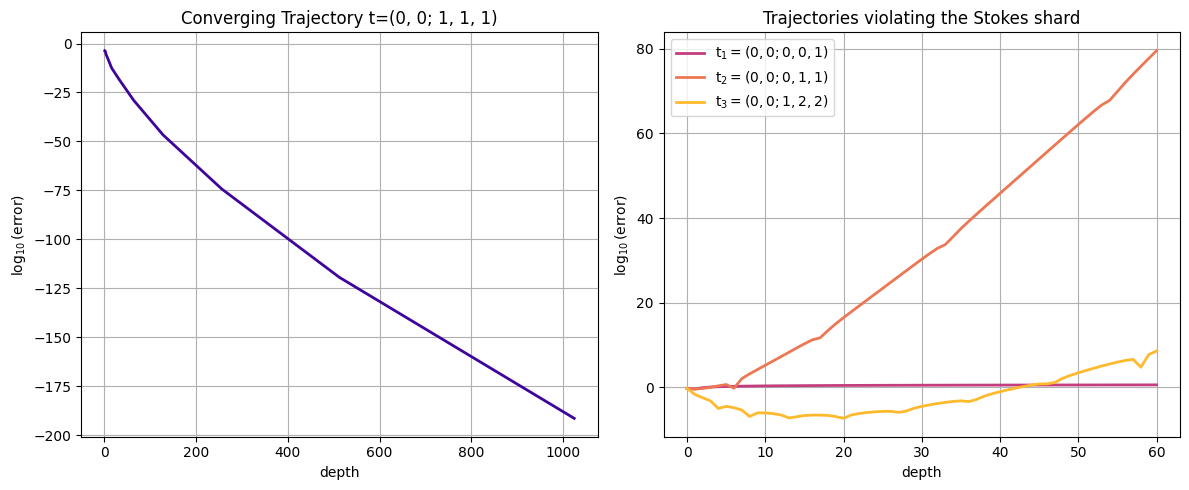

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

theme_colors = plt.cm.plasma(np.linspace(0, 0.85, 10))
converge_color = theme_colors[1]
diverging_colors = theme_colors[5:10:2]

ax1.plot(e1.df['depth'], e1.df['log10_error'], color=converge_color, linewidth=2)
ax1.set_xlabel('depth')
ax1.set_ylabel(r'$\log_{10}(\text{error})$')
ax1.set_title(f'Converging Trajectory t={trajectory_str(e1.trajectory)}')
ax1.grid(True)

dfs_violate = [e2.df1, e2.df2, e2.df3]
trajectories_violate = [e2.trajectory1, e2.trajectory2, e2.trajectory3]

for i, (df, trajectory, color) in enumerate(zip(dfs_violate, trajectories_violate, diverging_colors)):
    label_text = rf"t$_{i+1}={trajectory_str(trajectory)}$"
    ax2.plot(df['depth'], df['log10_error'], color=color, linewidth=2, label=label_text)

ax2.set_xlabel('depth')
ax2.set_ylabel(r'$\log_{10}(\text{error})$')
ax2.set_title('Trajectories violating the Stokes shard')
ax2.grid(True)
ax2.legend(loc='upper left', fontsize=10)

fig.savefig(
    "euler_convergence_vs_divergence.pdf",
    format="pdf",
    bbox_inches="tight",
)

plt.tight_layout()
plt.show()

## Example 3: Constructing many Apéry-like recurrences of order 3 that approximate $\gamma$

Note that some of these are in $\mathcal{T}^*_3$ and are proven to converge, while others are only in $\mathcal{T}_3$ and their convergence is only conjectured.

In [ ]:
from tqdm import tqdm

In [ ]:
e3 = SimpleNamespace()
e3.q = 3
e3.p = e3.q - 1
e3.cmf = MeijerG(m=e3.q, n=e3.p, p=e3.p, q=e3.q, z=1)
e3.start = Position({a0: 0, a1: 0, b0: 0, b1: 0, b2: 0})
e3.initial_values = initial_values(e3.p)
e3.max_depth = 200
e3.resolution = 10
e3.depths = list(range(0, e3.max_depth + 1, e3.resolution))

In [ ]:
e3.trajectories = [Position({a0: -x0, a1: -x1, b0: 1, b1: 1, b2: 1 + x2}) for x0, x1, x2 in itertools.product(range(4), repeat=3) if x0 >= x1]
e3.data = []
for trajectory in tqdm(e3.trajectories):
  e3.m = e3.cmf.trajectory_matrix(trajectory, e3.start).as_polynomial()
  e3.m_T = e3.m.inverse().transpose().as_polynomial()
  recurrence = LinearRecurrence(e3.m_T)
  e3.limits = recurrence.limit(e3.depths, 0, e3.initial_values * e3.m_T.companion_coboundary_matrix().subs({n: 0}))
  for i, limit in enumerate(e3.limits):
    e3.data.append({
      "depth": i * e3.resolution,
      "trajectory": trajectory,
      "recurrence": recurrence,
      "log10_error": log_error(limit.as_float(), euler),
      "normalized log_error": log_error(limit.as_float(), euler, base=sum(abs(t) for t in trajectory.values())),
      "delta": limit.delta(euler)
    })

100%|██████████| 40/40 [02:06<00:00,  3.16s/it]


In [ ]:
# Adding the recurrence discovered by Aptekarev et al. https://arxiv.org/abs/0902.1768
e3.aptekarev_recurrence = LinearRecurrence([-(16*n-15), 128*n**3 + 40*n**2 - 82*n - 45, -n**2*(256*n**3 - 240*n**2 + 64*n - 7), n**2*(n-1)**2*(16*n+1)])
e3.aptekarev_iv = Matrix([[0, 2, 31], [1, 3, 50]])
e3.aptekarev_limits = e3.aptekarev_recurrence.limit(e3.depths, 2, e3.aptekarev_iv)
for i, limit in enumerate(e3.aptekarev_limits):
  e3.data.append({
    "depth": i * e3.resolution,
    "trajectory": "Aptekarev et al.",
    "recurrence": e3.aptekarev_recurrence,
    "log10_error": log_error(limit.as_float(), euler),
    "normalized log_error": None,
    "delta": limit.delta(euler)
  })

In [ ]:
# Adding the recurrence discovered by Rivoal https://rivoal.perso.math.cnrs.fr/articles/eulerconstant.pdf
e3.rivoal_recurrence = LinearRecurrence([
    -(n + 3)**2 * (8*n + 11) * (8*n + 19),
    (n + 3) * (8*n + 11) * (24*n**2 + 145*n + 215),
    -(8*n + 27) * (24*n**3 + 105*n**2 + 124*n + 25),
    (n + 2)**2 * (8*n + 19) * (8*n + 27),
])

e3.rivoal_iv = Matrix([
    [-4, 16, 77],
    [4, 28, 130],
])

e3.rivoal_limits = e3.rivoal_recurrence.limit(e3.depths, 0, e3.rivoal_iv)
for i, limit in enumerate(e3.rivoal_limits):
  e3.data.append({
    "depth": i * e3.resolution,
    "trajectory": "Rivoal",
    "recurrence": e3.rivoal_recurrence,
    "log10_error": log_error(limit.as_float(), euler),
    "normalized log_error": None,
    "delta": limit.delta(euler)
  })

In [ ]:
e3.df = pd.DataFrame(e3.data)
display(e3.df[e3.df['depth'] == e3.max_depth].sort_values(by="log10_error"))

,depth,trajectory,recurrence,log10_error,normalized log_error,delta
776,200,"{a0: -3, a1: -3, b0: 1, b1: 1, b2: 1}",(-17179869184*n**19 + 15569256448*n**18 + 1936...,-162.982207,-170.797470,-0.933553
692,200,"{a0: -3, a1: -2, b0: 1, b1: 1, b2: 1}",(-2641807540224*n**22 - 28458195222528*n**21 +...,-147.895490,-163.766062,-0.939135
440,200,"{a0: -2, a1: -2, b0: 1, b1: 1, b2: 1}",(-1417176*n**15 - 7735419*n**14 + 29996892*n**...,-134.946957,-159.682014,-0.923927
608,200,"{a0: -3, a1: -1, b0: 1, b1: 1, b2: 1}",(-134217728*n**16 - 1323565056*n**15 - 2413854...,-128.374379,-151.904717,-0.946996
356,200,"{a0: -2, a1: -1, b0: 1, b1: 1, b2: 1}",(-10077696*n**16 - 121557834*n**15 - 503507016...,-116.235095,-149.373396,-0.933888
797,200,"{a0: -3, a1: -3, b0: 1, b1: 1, b2: 2}",(-1099511627776*n**25 + 229548587220992*n**24 ...,-101.633273,-101.633273,-0.962374
188,200,"{a0: -1, a1: -1, b0: 1, b1: 1, b2: 1}",(-2048*n**11 - 15744*n**10 - 34784*n**9 + 2931...,-101.257793,-144.867150,-0.909212
524,200,"{a0: -3, a1: 0, b0: 1, b1: 1, b2: 1}",(-134217728*n**16 - 2082340864*n**15 - 1375673...,-100.221295,-128.794106,-0.958317
272,200,"{a0: -2, a1: 0, b0: 1, b1: 1, b2: 1}",(-157464*n**13 - 1933308*n**12 - 9757746*n**11...,-91.103226,-130.339250,-0.947637
713,200,"{a0: -3, a1: -2, b0: 1, b1: 1, b2: 2}",(-2579890176*n**22 + 407933190144*n**21 - 1065...,-87.189767,-91.370660,-0.965424


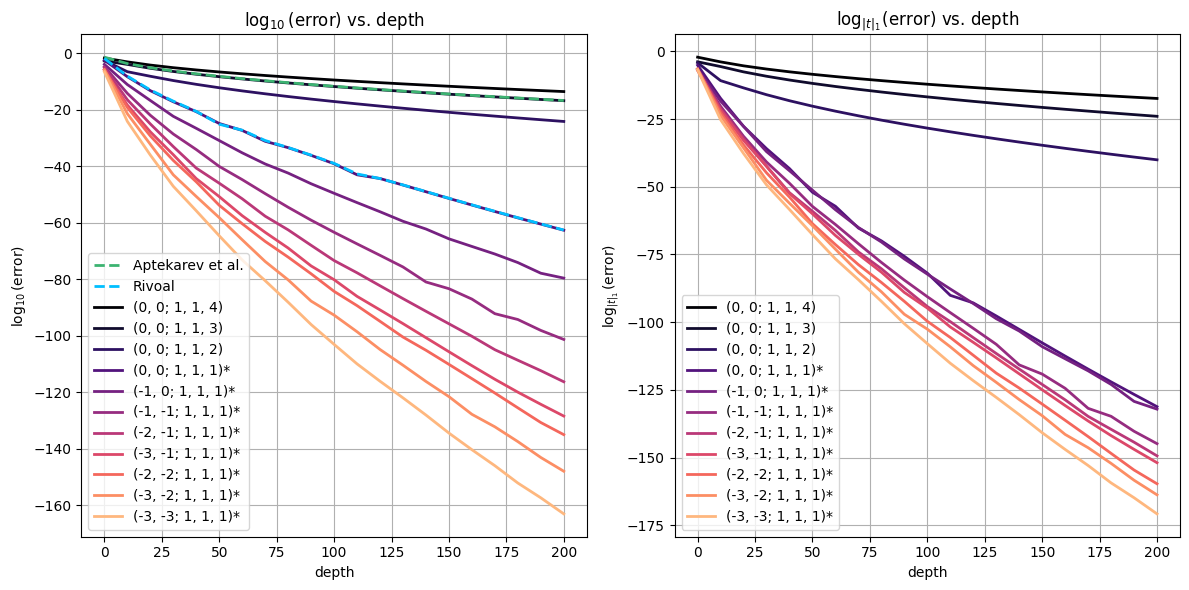

In [ ]:
# Exploring the behavior of increasing a vs increasing b values at different depths

trajectories = [
    Position({a0: 0, a1: 0, b0: 1, b1: 1, b2: 4}),
    Position({a0: 0, a1: 0, b0: 1, b1: 1, b2: 3}),
    Position({a0: 0, a1: 0, b0: 1, b1: 1, b2: 2}),
    Position({a0: 0, a1: 0, b0: 1, b1: 1, b2: 1}),
    Position({a0: -1, a1: 0, b0: 1, b1: 1, b2: 1}),
    Position({a0: -1, a1: -1, b0: 1, b1: 1, b2: 1}),
    Position({a0: -2, a1: -1, b0: 1, b1: 1, b2: 1}),
    Position({a0: -3, a1: -1, b0: 1, b1: 1, b2: 1}),
    Position({a0: -2, a1: -2, b0: 1, b1: 1, b2: 1}),
    Position({a0: -3, a1: -2, b0: 1, b1: 1, b2: 1}),
    Position({a0: -3, a1: -3, b0: 1, b1: 1, b2: 1})
]

gradual_colors = plt.cm.magma(np.linspace(0, 0.85, len(trajectories)))

fig = plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.xlabel('depth')
plt.ylabel(r'$\log_{10}(\text{error})$')
plt.title(r'$\log_{10}(\text{error})$ vs. depth')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.xlabel('depth')
plt.ylabel(r'$\log_{|t|_1}(\text{error})$')
plt.title(r'$\log_{|t|_1}(\text{error})$ vs. depth')
plt.grid(True)

for trajectory, color in [("Aptekarev et al.", "mediumseagreen"), ("Rivoal", "deepskyblue")]:
  df = e3.df[e3.df['trajectory'] == trajectory]
  plt.subplot(1, 2, 1)
  plt.plot(df['depth'], df['log10_error'], linewidth=2, label=trajectory, color=color, linestyle="dashed", zorder=100)

for trajectory, color in zip(trajectories, gradual_colors):
    label = trajectory_str(trajectory)
    if is_proven(trajectory):
      label += "*"

    df = e3.df[e3.df['trajectory'] == trajectory]

    plt.subplot(1, 2, 1)
    plt.plot(df['depth'], df['log10_error'], linewidth=2, label=label, color=color)

    plt.subplot(1, 2, 2)
    plt.plot(df['depth'], df['normalized log_error'], linewidth=2, label=label, color=color)

plt.subplot(1, 2, 1)
plt.legend(loc="lower left")

plt.subplot(1, 2, 2)
plt.legend(loc="lower left")

plt.tight_layout()

fig.savefig(
    "euler_compare.pdf",
    format="pdf",
    bbox_inches="tight",
)

plt.show()

## Example 4: A gauge equivalence between the $(0, 0; 1, 1, 1)$ trajectory and Rivoal's construction

In [ ]:
G = Matrix([
[ 0,          (8*n + 11)/(n + 1)**2,                                  (24*n**2 + 97*n + 94)/((n + 1)**2*(n + 2))],
[-1,    (3*n**2 - n - 7)/(n + 1)**2,          (15*n**4 + 69*n**3 + 66*n**2 - 78*n - 111)/((n + 1)**2*(n + 2)**2)],
[ 2, (-6*n**2 - 6*n + 3)/(n + 1)**2, (8*n**5 + 21*n**4 - 38*n**3 - 131*n**2 - 48*n + 53)/((n + 1)**2*(n + 2)**2)]])

M_inv = e3.cmf.trajectory_matrix(Position({a0: 0, a1: 0, b0: 1, b1: 1, b2: 1}), e3.start).inverse().transpose()

assert e3.rivoal_recurrence.recurrence_matrix == (n+1)**2 * M_inv.coboundary(G)

## Example 5: Constructing an Apéry-like recurrence of order 4 conjectured to approximate $\gamma$

This construction is of order 4 hence not proven to converge in the paper, although numerical analysis strongly suggests it does.

In [ ]:
e4 = SimpleNamespace()
e4.q = 4
e4.p = e4.q - 1
e4.initial_values = initial_values(e4.p)
e4.start = Position({a0: 0, a1: 0, a2: 0, b0: 0, b1: 0, b2: 0, b3: 0})
e4.cmf = MeijerG(m=e4.q, n=e4.p, p=e4.p, q=e4.q, z=1)
display(e4.cmf)

MeijerG((4, 3, 3, 4, 1))

In [ ]:
e4.trajectory = Position({a0: 0, a1: 0, a2: 0, b0: 1, b1: 1, b2: 1, b3: 1})
e4.m = e4.cmf.trajectory_matrix(e4.trajectory, e4.start).as_polynomial()
e4.m_T = e4.m.inverse().transpose().as_polynomial()
display(e4.m_T)

Matrix([
[               20*n**3 + 61*n**2 + 66*n + 35,                  -45*n**2 - 86*n - 21,                    36*n + 46,              -10],
[               10*n**4 + 20*n**3 - 20*n - 20,        -20*n**3 - 14*n**2 + 36*n + 10,           15*n**2 - 2*n - 27,          6 - 4*n],
[       4*n**5 - 20*n**3 - 20*n**2 - 4*n + 10, -6*n**4 + 16*n**3 + 39*n**2 - 6*n - 3, 4*n**3 - 17*n**2 - 18*n + 13,  -n**2 + 6*n - 3],
[n**6 - 6*n**5 - 15*n**4 + 14*n**2 + 12*n - 4,      2*n*(9*n**3 + 6*n**2 - 15*n - 2), -12*n**3 + 6*n**2 + 24*n - 4, 3*n**2 - 6*n + 1]])

In [ ]:
e4.initial_values = initial_values(e4.p)
display(e4.initial_values)

Matrix([
[1, 1, -1,  0],
[1, 2,  1, -1]])

In [ ]:
e4.limit = e4.m_T.limit({n: 1}, 1000, {n: 0}, e4.initial_values)
print(f"Convergence limit: {e4.limit.as_float()}")
print(f"Log10 Error: {log_error(e4.limit.as_float(), euler)}")
print(f"Delta: {e4.limit.delta(euler)}")

Convergence limit: 0.577215664901532860606512090082402431042159335939923598805767234884867726777664670936947063291746749514631447249807082480960504014486542836224173997644923536253500333742937337737673942792595258247094916008735203948165670853233151776611528621199501507984793745085705739988548379556260648556919147
Log10 Error: -268.38328324682357
Delta: -0.9181834155184972


In [ ]:
e4.recurrence = LinearRecurrence(e4.m_T)
display(e4.recurrence)

LinearRecurrence([-729*n**16 - 17334*n**15 - 186345*n**14 - 1197164*n**13 - 5114565*n**12 - 15275370*n**11 - 32520349*n**10 - 48910008*n**9 - 48636256*n**8 - 22267976*n**7 + 20124548*n**6 + 55369448*n**5 + 65419720*n**4 + 49033280*n**3 + 22308852*n**2 + 4694048*n + 33408, 2916*n**19 + 110889*n**18 + 1936242*n**17 + 20574791*n**16 + 148653576*n**15 + 772681205*n**14 + 2980505962*n**13 + 8666500555*n**12 + 19055587516*n**11 + 31292164830*n**10 + 36704225128*n**9 + 26106350004*n**8 - 247114484*n**7 - 29719189150*n**6 - 46581658036*n**5 - 43808785072*n**4 - 27146500432*n**3 - 9882493184*n**2 - 1266776880*n + 201090384, -4374*n**22 - 173988*n**21 - 3119418*n**20 - 32802960*n**19 - 216905502*n**18 - 843865472*n**17 - 813148566*n**16 + 12518978936*n**15 + 95654141436*n**14 + 399219486124*n**13 + 1155750064408*n**12 + 2460489254868*n**11 + 3883562473946*n**10 + 4386767521812*n**9 + 3017753331412*n**8 - 73927819068*n**7 - 3461286309510*n**6 - 5427232458956*n**5 - 5189449744056*n**4 - 3388076079

In [ ]:
e4.recurrence_initial_values = e4.initial_values * e4.m_T.companion_coboundary_matrix().subs({n: 0})
display(e4.recurrence_initial_values)

Matrix([
[1, 5,  808, 273432],
[1, 9, 1404, 484956]])

In [ ]:
e4.data = []
e4.depths = [2**i for i in range(11)]
e4.recurrence_limit_list = e4.recurrence.limit(e4.depths, 0, e4.recurrence_initial_values)
for depth, limit in zip(e4.depths, e4.recurrence_limit_list):
  e4.data.append({"depth": depth, "log10 error": log_error(limit.as_float(), euler), "delta": limit.delta(euler)})

e4.df = pd.DataFrame(e4.data)
display(e4.df)

,depth,log10 error,delta
0,1,-2.453640,-0.571213
1,2,-3.448752,-0.570534
2,4,-4.907071,-0.596414
3,8,-6.519742,-0.679417
4,16,-10.752851,-0.723068
5,32,-17.331771,-0.769523
6,64,-30.506168,-0.807821
7,128,-52.788795,-0.844549
8,256,-92.085833,-0.873803
9,512,-158.991437,-0.898696


## Example 6: Constructing an Apéry-like recurrence of order 5 that approximates $\gamma$

This construction is of order 4 hence not proven to converge in the paper, although numerical analysis strongly suggests it does.

In [ ]:
e5 = SimpleNamespace()
e5.q = 5
e5.p = e5.q - 1
e5.initial_values = initial_values(e5.p)
e5.start = Position({a0: 0, a1: 0, a2: 0, a3: 0, b0: 0, b1: 0, b2: 0, b3: 0, b4: 0})
e5.cmf = MeijerG(m=e5.q, n=e5.p, p=e5.p, q=e5.q, z=1)
display(e5.cmf)

MeijerG((5, 4, 4, 5, 1))

In [ ]:
e5.trajectory = Position({a0: 0, a1: 0, a2: 0, a3: 0, b0: 1, b1: 1, b2: 1, b3: 1, b4: 1})
e5.m = e5.cmf.trajectory_matrix(e5.trajectory, e5.start).as_polynomial()
e5.m_T = e5.m.inverse().transpose().as_polynomial()
display(e5.m_T)

Matrix([
[                                70*n**4 + 281*n**3 + 428*n**2 + 308*n + 126,                             -224*n**3 - 667*n**2 - 632*n - 84,                               280*n**2 + 575*n + 400,                            -160*n - 125,                           35],
[                        35*n**5 + 105*n**4 + 70*n**3 - 70*n**2 - 105*n - 70,                   -105*n**4 - 195*n**3 + 50*n**2 + 280*n + 35,                    126*n**3 + 103*n**2 - 142*n - 224,                    -70*n**2 + 35*n + 70,                    15*n - 20],
[                15*n**6 + 20*n**5 - 55*n**4 - 120*n**3 - 55*n**2 + 5*n + 35,           -40*n**5 + 10*n**4 + 216*n**3 + 188*n**2 - 92*n - 9,            45*n**4 - 71*n**3 - 198*n**2 - 78*n + 109,          -24*n**3 + 73*n**2 + 28*n - 34,           5*n**2 - 20*n + 10],
[       5*n**7 - 10*n**6 - 60*n**5 - 45*n**4 + 45*n**3 + 55*n**2 + 30*n - 15, -10*n**6 + 60*n**5 + 135*n**4 - 36*n**3 - 188*n**2 + 17*n - 1,  10*n**5 - 85*n**4 - 62*n**3 + 114*n**2 + 144*n -

In [ ]:
e5.initial_values = initial_values(e5.p)
display(e5.initial_values)

Matrix([
[1, 2, 1, 1, 0],
[1, 3, 3, 1, 1]])

In [ ]:
e5.limit = e5.m_T.limit({n: 1}, 1000, {n: 0}, e5.initial_values)
print(f"Convergence limit: {e5.limit.as_float()}")
print(f"Log10 Error: {log_error(e5.limit.as_float(), euler)}")
print(f"Delta: {e5.limit.delta(euler)}")

Convergence limit: 0.577215664901532860606512090082402431042159335939923598805767234884867726777664670936947063291746749514631447249807082480960504014486542836224173997644923536253500333742937337737673942792595258247094916008735203948165670853233151776611528621199501507984793745085705740029921354786146694030306503330263378688079493037
Log10 Error: -288.153552838017
Delta: -0.9173375890139981


In [ ]:
e5.recurrence = LinearRecurrence(e5.m_T)
display(e5.recurrence)

LinearRecurrence([-1048576*n**30 - 65372160*n**29 - 1929403392*n**28 - 35874809088*n**27 - 471730610912*n**26 - 4667567809320*n**25 - 36098823819199*n**24 - 223746824624921*n**23 - 1130477836012238*n**22 - 4710111882843480*n**21 - 16305431886923222*n**20 - 47095881527695319*n**19 - 113612964156255436*n**18 - 228321740290844423*n**17 - 379274645258569690*n**16 - 511606012278564537*n**15 - 536604317115241604*n**14 - 379574944818651731*n**13 - 35933224839711683*n**12 + 414611029307570130*n**11 + 846172584990409074*n**10 + 1137825299986690631*n**9 + 1209566965785703411*n**8 + 1052404578461769450*n**7 + 745449252078572617*n**6 + 421163278680381398*n**5 + 184631985615832825*n**4 + 60761883718476900*n**3 + 14404089290214025*n**2 + 2297542375423000*n + 199226238340300, 5242880*n**34 + 446398464*n**33 + 18132454400*n**32 + 467729651968*n**31 + 8604424171872*n**30 + 120181515700488*n**29 + 1324872813242563*n**28 + 11830126001918001*n**27 + 87130261735993460*n**26 + 536258341749722446*n**25 + 278

In [ ]:
e5.recurrence_initial_values = e5.initial_values * e5.m_T.companion_coboundary_matrix().subs({n: 0})
display(e5.recurrence_initial_values)

Matrix([
[1,  6,  5236, 13960332,  93001762944],
[1, 11, 10104, 25806168, 153463555584]])

In [ ]:
e5.data = []
e5.depths = [2**i for i in range(11)]
e5.recurrence_limit_list = e5.recurrence.limit(e5.depths, 0, e5.recurrence_initial_values)
for depth, limit in zip(e5.depths, e5.recurrence_limit_list):
  e5.data.append({"depth": depth, "log10 error": log_error(limit.as_float(), euler), "delta": limit.delta(euler)})

e5.df = pd.DataFrame(e5.data)
display(e5.df)

,depth,log10 error,delta
0,1,-2.045597,-0.775881
1,2,-3.516988,-0.695990
2,4,-3.361544,-0.798553
3,8,-6.778042,-0.737113
4,16,-8.841568,-0.809127
5,32,-15.074893,-0.829910
6,64,-27.076854,-0.850156
7,128,-51.000139,-0.865243
8,256,-89.824608,-0.887076
9,512,-163.779412,-0.903137
